# Extract Features

1. `relation_extraction.ipynb`


In [1]:
import os, sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

notebook_dir = os.getcwd()
sys.path.append(os.path.join(notebook_dir, '../'))

from data_processing import DataProcessing
from feature_extraction import SpacyFeatureExtraction

In [2]:
pd.set_option('max_colwidth', 800)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
base_data_path = os.path.join(notebook_dir, '../data')
synthetic_dataset_path = "combined_datasets/tolsa_naacl_2026_2027-final/tolsa_naacl_2026_2027_main_columns_v1.csv"
full_path = os.path.join(base_data_path, synthetic_dataset_path)
print(full_path)
df = DataProcessing.load_from_file(full_path, 'csv', sep=',')
df.head(3)

/Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/notebook_experiments/../data/combined_datasets/tolsa_naacl_2026_2027-final/tolsa_naacl_2026_2027_main_columns_v1.csv


,Base Sentence,Ground Truth,Dataset Name
0,"Sebastian, a financial analyst forecasts that the stock price at Apple will decrease in 2027 Q3.",1,synthetic
1,"On August 22, 2024, Goldman Sachs speculates that the operating cash flow at Amazon will likely increase.",1,synthetic
2,"Citigroup predicts on September 15, 2026, the S&P 500 index could climb moderately.",1,synthetic


In [4]:
# df = df.loc[:40, ]
# df.head(3)

## Embed Sentences

In [5]:
spacy_fe = SpacyFeatureExtraction(df, 'Base Sentence')
embeddings_df = spacy_fe.sentence_embeddings_extraction(attach_to_df=True)
embeddings_df.head(3)

Pipeline components: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


100%|██████████| 27032/27032 [03:13<00:00, 139.65it/s]


,Base Sentence,Ground Truth,Dataset Name,Base Sentence Embedding
0,"Sebastian, a financial analyst forecasts that the stock price at Apple will decrease in 2027 Q3.",1,synthetic,"[-0.25060558, 0.29229578, -0.017285168, 0.038140394, 0.0963994, -0.037416093, -0.06957313, -0.007136556, 0.024509327, 1.6016587, -0.34629405, 0.06423144, 0.0759401, -0.043366063, 0.028066503, -0.088097796, -0.10720584, 1.1028299, -0.13490605, -0.03133966, 0.01581494, 0.11239001, 0.015270364, -0.132077, -0.09321812, 0.21778066, -0.15241832, 0.058787838, 0.12732345, 0.10359114, -0.02299425, -0.051419333, -0.0053153452, 0.14624679, 0.062254164, 0.0137916505, 0.048265338, 0.07401835, 0.011454565, -0.10789546, -0.00031105243, 0.058829717, 0.19753951, 0.03220825, 0.07321394, 0.03844084, -0.13203089, -0.23014757, -0.00048173053, -0.040234044, -0.0045900587, -0.057571426, -0.111653976, 0.005960817, 0.102194555, -0.11540408, -0.04786217, -0.07672823, -0.019875532, -0.22174487, -0.05033613, -0.1..."
1,"On August 22, 2024, Goldman Sachs speculates that the operating cash flow at Amazon will likely increase.",1,synthetic,"[-0.1733585, 0.37392026, 0.043182198, 0.013803309, -0.130146, 0.058297455, -0.08806322, -0.061455004, 0.08468879, 1.615256, -0.18676272, 0.055018723, 0.12108646, 0.03748376, -0.1931938, 0.078024045, -0.13925335, 1.06406, -0.13687566, -7.245205e-05, -0.007806751, 0.12331418, 0.041915752, -0.12733147, -0.0073575946, 0.07848731, -0.09402015, 0.0059286496, 0.006340889, 0.09216319, -0.0015970342, -0.054558992, 0.019748084, 0.111862384, -0.041304383, 0.030047486, 0.00241853, 0.104500316, -0.004456042, -0.14039063, -0.04280888, 0.043156244, 0.15911345, -0.023679763, 0.079980254, 0.027360294, -0.06524451, -0.13068046, -0.00056890177, 0.09530535, 0.10297205, 0.05030324, -0.10905834, 0.030973405, 0.060653724, -0.02065205, 0.054794498, -0.095081, -0.09953764, -0.091471344, 0.04152286, -0.09350929..."
2,"Citigroup predicts on September 15, 2026, the S&P 500 index could climb moderately.",1,synthetic,"[-0.06567979, 0.30294448, -0.043433182, 0.014376875, 0.06997293, -0.050046295, -0.15087934, 0.06535687, 0.07857625, 1.3254025, -0.26242998, 0.0136645585, 0.059258733, 0.100946166, -0.14733058, 0.045119565, -0.034887306, 0.98371875, -0.061256878, -0.046074312, -0.0095430575, 0.1230978, 0.07190538, -0.12799029, 0.06965713, 0.16736789, -0.067201436, -0.0102841845, 0.06417377, 0.050679132, 0.018230515, -0.06384325, 0.10261912, 0.026694981, -0.027239878, -0.026259251, 0.07179767, 0.08206459, 0.03952482, 0.026378624, -0.0007684368, -0.049795497, 0.12723812, -0.0668573, 0.03082236, -0.047309566, -0.05804901, -0.15211925, 0.08117881, 0.03333862, -0.07464844, 0.06109482, -0.08465331, -0.009247125, -0.036158375, 0.043926373, -0.063594684, 0.05125087, 0.008436713, -0.15157424, -0.042720873, 0.049..."


In [6]:
embeddings = np.array(embeddings_df["Base Sentence Embedding"].to_list())
embeddings

array([[-0.25060558,  0.29229578, -0.01728517, ..., -0.09221037,
        -0.01505816,  0.06427389],
       [-0.1733585 ,  0.37392026,  0.0431822 , ..., -0.0870902 ,
        -0.13688491,  0.05465063],
       [-0.06567979,  0.30294448, -0.04343318, ..., -0.03391431,
        -0.04408544,  0.02569138],
       ...,
       [ 0.0250177 ,  0.24548335, -0.03176577, ..., -0.02885974,
        -0.03768811,  0.02426148],
       [-0.09468294,  0.18164851, -0.05155824, ..., -0.01514282,
         0.02396918,  0.02695845],
       [-0.0943795 ,  0.19737864, -0.07383683, ...,  0.00198827,
        -0.11966009,  0.02507852]], shape=(27032, 300), dtype=float32)

## Cluster

### Types of clustering


![title](../misc/kmeansAndTsnePlotComparisions.png)

- Source - https://stackoverflow.com/a/32370538
- Posted by Reblochon Masque, modified by community. See post 'Timeline' for change history
- Retrieved 2025-11-18, License - CC BY-SA 4.0

### KMeans x TSNE

In [7]:
def plot_clusters(X, n_clusters):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit(X)
    tsne = TSNE(n_components=n_clusters, learning_rate='auto', init='random', perplexity=3).fit_transform(X)
    print(tsne)

    # Get cluster labels and cluster centers
    labels = kmeans.labels_
    print(labels)
    centers = kmeans.cluster_centers_
    # print(centers)

    # Create scatter plot
    
    plt.figure(figsize=(8, 6))
    # Plot data points colored by cluster labels
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=100, alpha=0.6)
    # Plot cluster centers
    plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, marker='X')

    # Add title and axis labels
    plt.title('KMeans Clustering Scatter Plot')
    plt.xlabel('X-axis')
    plt.ylabel('Y-axis')

    # Show the plot
    plt.show()


[[ -7.855063  -77.35223  ]
 [ -5.3645535 -63.508347 ]
 [  1.9453835 -49.853546 ]
 ...
 [ 61.554688   48.885757 ]
 [ 61.732903   48.583836 ]
 [ 61.239246   49.370476 ]]
[0 0 0 ... 1 1 1]


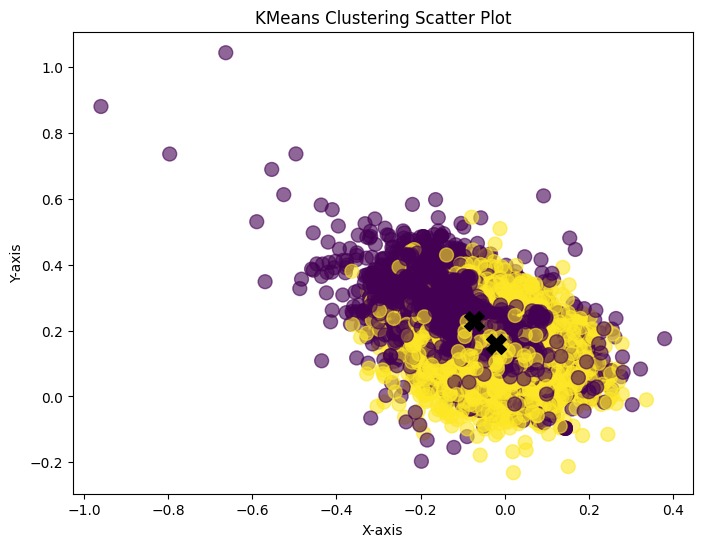

In [8]:
plot_clusters(embeddings, 2)

### KMeans

In [ ]:
def plot_clusters(X, df, n_clusters, text_column='Base Sentence'):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit(X)
    
    labels = kmeans.labels_
    centers = kmeans.cluster_centers_
    
    plt.figure(figsize=(12, 8))
    
    # Plot data points colored by cluster labels
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=100, alpha=0.6)
    
    # Plot cluster centers
    plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, marker='X', label='Centroids')
    
    # Add text labels with shortened sentences
    # for i, (x, y) in enumerate(X[:, :2]):
    #     if i < len(df):
    #         sentence = df.iloc[i][text_column]
    #         # shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #         plt.annotate(sentence, (x, y), fontsize=7, alpha=0.6, rotation=7)
    
    plt.title(f'KMeans Clustering (first 2 embedding dimensions)\nTotal points: {len(X)}, Labeled: {len(df)}')
    plt.xlabel('Embedding Dimension 1')
    plt.ylabel('Embedding Dimension 2')
    plt.legend()
    plt.colorbar(scatter)
    plt.tight_layout()
    plt.show()

ValueError: 
Operating profit for the abrasives, engineering materials and petroleum services concern was $19.2 million, or 91 cents a share, up 3% from $18.7 million, or 87 cents a share.
                                                                                             ^
ParseException: Expected end of text, found '$'  (at char 93), (line:1, col:94)

Error in callback <function _draw_all_if_interactive at 0x11b46bce0> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
Operating profit for the abrasives, engineering materials and petroleum services concern was $19.2 million, or 91 cents a share, up 3% from $18.7 million, or 87 cents a share.
                                                                                             ^
ParseException: Expected end of text, found '$'  (at char 93), (line:1, col:94)

ValueError: 
Operating profit for the abrasives, engineering materials and petroleum services concern was $19.2 million, or 91 cents a share, up 3% from $18.7 million, or 87 cents a share.
                                                                                             ^
ParseException: Expected end of text, found '$'  (at char 93), (line:1, col:94)

<Figure size 1200x800 with 2 Axes>

In [ ]:
plot_clusters(embeddings, embeddings_df, 2)

### TSNE

/var/folders/78/9z0b45fx1xqbwxh8vk97lcfh0000gn/T/ipykernel_29153/3528905380.py:7: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = plt.scatter(tsne[:, 0], tsne[:, 1], s=100, alpha=0.6, cmap='viridis')


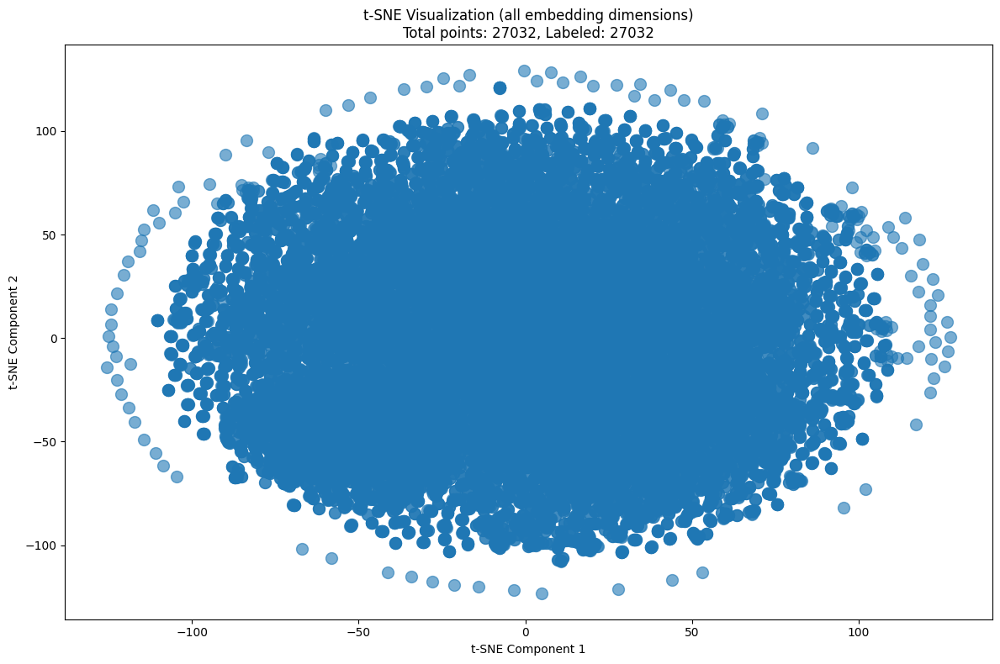

In [20]:
def plot_tsne(X, df, text_column='Base Sentence'):
    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=3, random_state=0).fit_transform(X)
    
    plt.figure(figsize=(12, 8))
    
    # Plot data points
    scatter = plt.scatter(tsne[:, 0], tsne[:, 1], s=100, alpha=0.6, cmap='viridis')
    
    # Add text labels with shortened sentences
    # for i, (x, y) in enumerate(tsne):
    #     if i < len(df):
    #         sentence = df.iloc[i][text_column]
    #         shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #         plt.annotate(shortened, (x, y), fontsize=8, alpha=0.7, rotation=45)
    
    plt.title(f't-SNE Visualization (all embedding dimensions)\nTotal points: {len(X)}, Labeled: {len(df)}')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.tight_layout()
    plt.show()

plot_tsne(embeddings, embeddings_df)

### KMeans x TSNE

In [21]:
def plot_kmeans_tsne(X, df, n_clusters, text_column='Base Sentence', return_clusters_df=True):
    # KMeans clustering on full dimensional data
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit(X)
    labels = kmeans.labels_
    
    # t-SNE dimensionality reduction on data only
    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=2, random_state=0).fit_transform(X)
    
    # Create dataframe with cluster assignments and t-SNE coordinates
    clusters_df = df.copy()
    clusters_df['Cluster'] = labels
    clusters_df['tSNE_1'] = tsne[:, 0]
    clusters_df['tSNE_2'] = tsne[:, 1]
    
    plt.figure(figsize=(12, 8))
    
    # Plot t-SNE reduced data colored by KMeans cluster labels
    scatter = plt.scatter(tsne[:, 0], tsne[:, 1], c=labels, cmap='viridis', s=100, alpha=0.6)
    
    # # Add text labels with shortened sentences
    # for i, (x, y) in enumerate(tsne):
    #     if i < len(df):
    #         sentence = df.iloc[i][text_column]
    #         shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #         plt.annotate(shortened, (x, y), fontsize=8, alpha=0.7, rotation=45)
    
    plt.title(f'KMeans Clustering with t-SNE Visualization\nClusters: {n_clusters}, Total points: {len(X)}, Labeled: {len(df)}')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()

    if return_clusters_df:
        return clusters_df

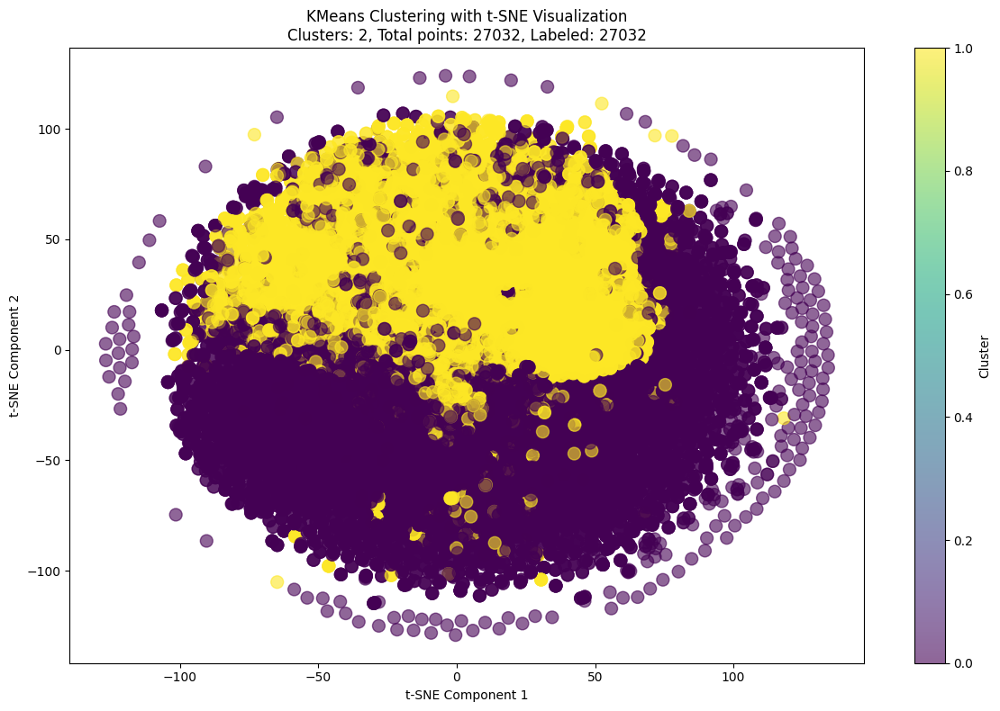

In [22]:
# Usage for getting dataframe
clusters_df = plot_kmeans_tsne(embeddings, embeddings_df, 2)
# clusters_df

In [13]:
def get_filt_df(df, col_name, entry):
    filt_cluster = (df[col_name] == entry)
    cluster_df = df[filt_cluster]
    return cluster_df

In [14]:
cluster_labels = clusters_df['Cluster'].unique()
cluster_labels

array([0, 1], dtype=int32)

In [15]:
cluster_dfs = []
cluster_labels = clusters_df['Cluster'].unique()
for cluster_label in cluster_labels: 
    cluster_df = get_filt_df(clusters_df, 'Cluster', cluster_label)
    cluster_dfs.append(cluster_df)

cluster_dfs

[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         Base Sentence  \
 0                                                                                                                                                                                           

In [16]:
# DataProcessing.concat_dfs(cluster_dfs)

### KMeans x TSNE with Centers

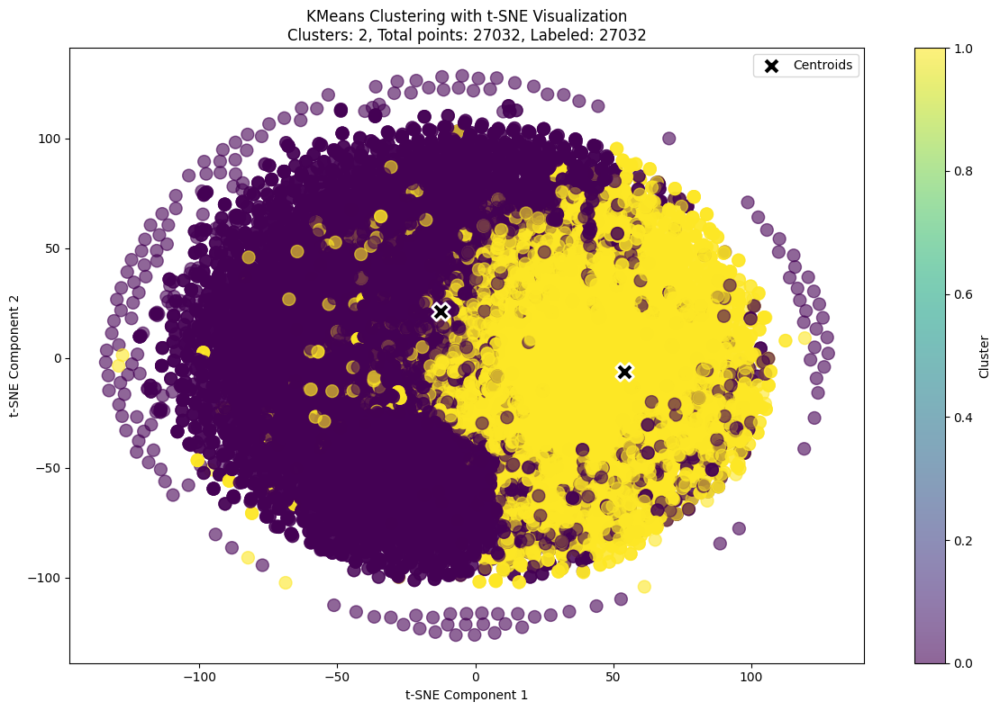

In [23]:
def plot_kmeans_tsne(X, df, n_clusters, text_column='Base Sentence'):
    # KMeans clustering on full dimensional data
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit(X)
    labels = kmeans.labels_
    centers = kmeans.cluster_centers_
    
    # t-SNE dimensionality reduction on data + centroids
    X_with_centers = np.vstack([X, centers])
    tsne_result = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=2, random_state=0).fit_transform(X_with_centers)
    
    # Split back into data points and centroids
    tsne = tsne_result[:-n_clusters]
    centers_tsne = tsne_result[-n_clusters:]
    
    plt.figure(figsize=(12, 8))
    
    # Plot t-SNE reduced data colored by KMeans cluster labels
    scatter = plt.scatter(tsne[:, 0], tsne[:, 1], c=labels, cmap='viridis', s=100, alpha=0.6)
    
    # Plot centroids
    plt.scatter(centers_tsne[:, 0], centers_tsne[:, 1], c='black', s=200, marker='X', label='Centroids', edgecolors='white', linewidths=2)
    
    # # Add text labels
    # for i, (x, y) in enumerate(tsne):
    #     if i < len(df):
    #         sentence = df.iloc[i][text_column]
    #         shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #         plt.annotate(shortened, (x, y), fontsize=8, alpha=0.7, rotation=45)
    
    plt.title(f'KMeans Clustering with t-SNE Visualization\nClusters: {n_clusters}, Total points: {len(X)}, Labeled: {len(df)}')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.legend()
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()

# Usage
plot_kmeans_tsne(embeddings, embeddings_df, 2)

### KMeans x TSNE with ...

X shape: (27032, 300)
df length: 27032
Labels: [0 0 0 ... 1 1 1]
t-SNE shape: (27032, 2)
t-SNE sample: [[ 77.50995  -41.022507]
 [ 66.272766 -19.774899]
 [ 48.475185 -13.726694]]
Centers: [[  0.98941976 -25.850016  ]
 [ -0.8971297   34.007164  ]]


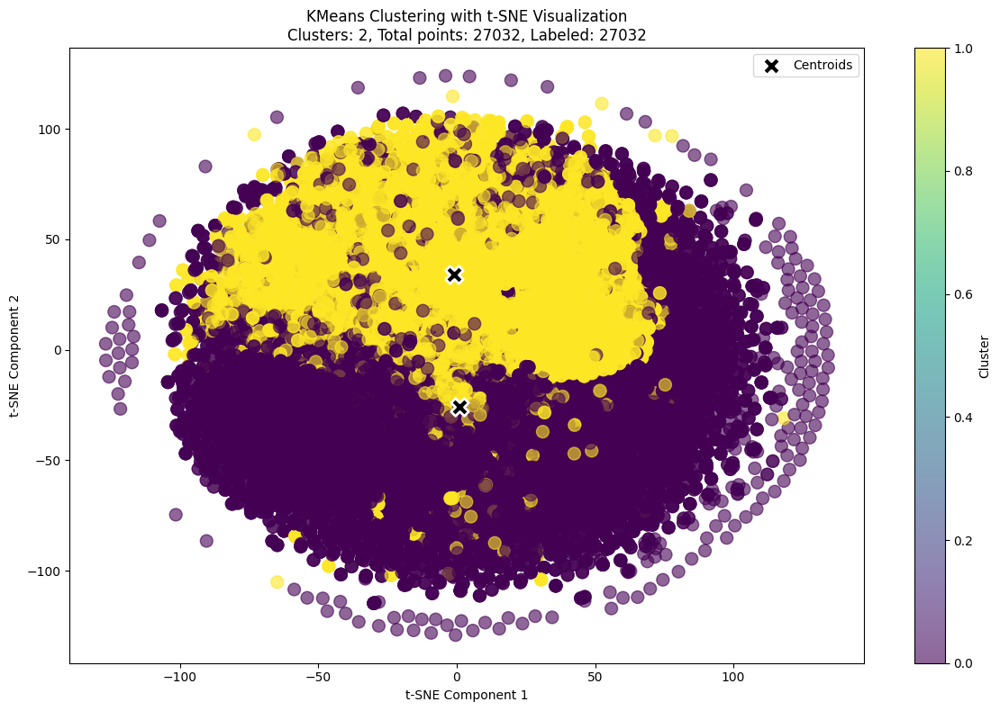

In [24]:
def plot_kmeans_tsne(X, df, n_clusters, text_column='Base Sentence'):
    print(f"X shape: {X.shape}")
    print(f"df length: {len(df)}")
    
    # KMeans clustering on full dimensional data
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init="auto").fit(X)
    labels = kmeans.labels_
    print(f"Labels: {labels}")
    
    # t-SNE dimensionality reduction on data only
    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=2, random_state=0).fit_transform(X)
    print(f"t-SNE shape: {tsne.shape}")
    print(f"t-SNE sample: {tsne[:3]}")
    
    # Calculate centroid positions as mean of cluster members in t-SNE space
    centers_tsne = np.array([tsne[labels == i].mean(axis=0) for i in range(n_clusters)])
    print(f"Centers: {centers_tsne}")
    
    plt.figure(figsize=(12, 8))
    
    # Plot t-SNE reduced data colored by KMeans cluster labels
    scatter = plt.scatter(tsne[:, 0], tsne[:, 1], c=labels, cmap='viridis', s=100, alpha=0.6)
    
    # Plot centroids
    plt.scatter(centers_tsne[:, 0], centers_tsne[:, 1], c='black', s=200, marker='X', label='Centroids', edgecolors='white', linewidths=2)
    
    # Add text labels
    # for i, (x, y) in enumerate(tsne):
    #     if i < len(df):
    #         sentence = df.iloc[i][text_column]
    #         shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #         plt.annotate(shortened, (x, y), fontsize=8, alpha=0.7, rotation=45)
    
    plt.title(f'KMeans Clustering with t-SNE Visualization\nClusters: {n_clusters}, Total points: {len(X)}, Labeled: {len(df)}')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.legend()
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()

plot_kmeans_tsne(embeddings, embeddings_df, 2)

### Hierarchical

/var/folders/78/9z0b45fx1xqbwxh8vk97lcfh0000gn/T/ipykernel_29153/3280223755.py:14: UserWarning: Glyph 128077 (\N{THUMBS UP SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/78/9z0b45fx1xqbwxh8vk97lcfh0000gn/T/ipykernel_29153/3280223755.py:14: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/.venv_predictions/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128077 (\N{THUMBS UP SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/.venv_predictions/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128078 (\N{THUMBS DOWN SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


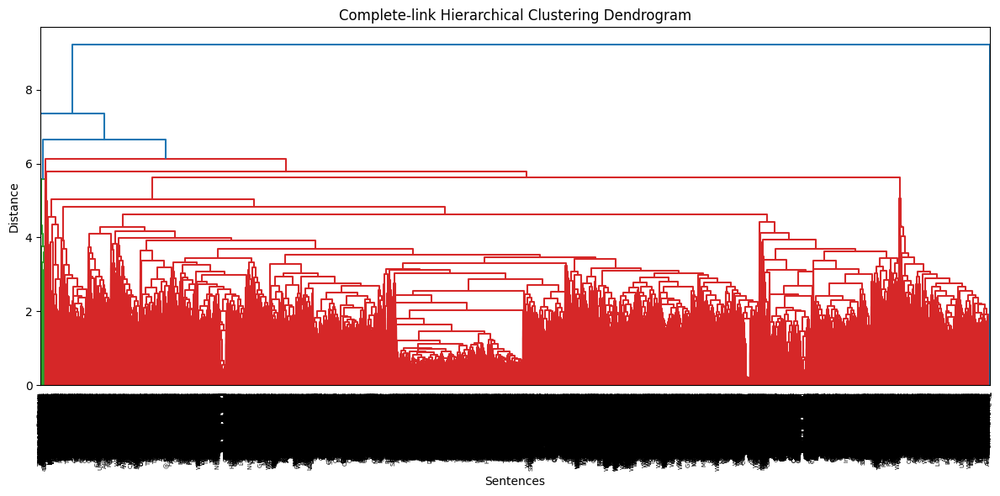

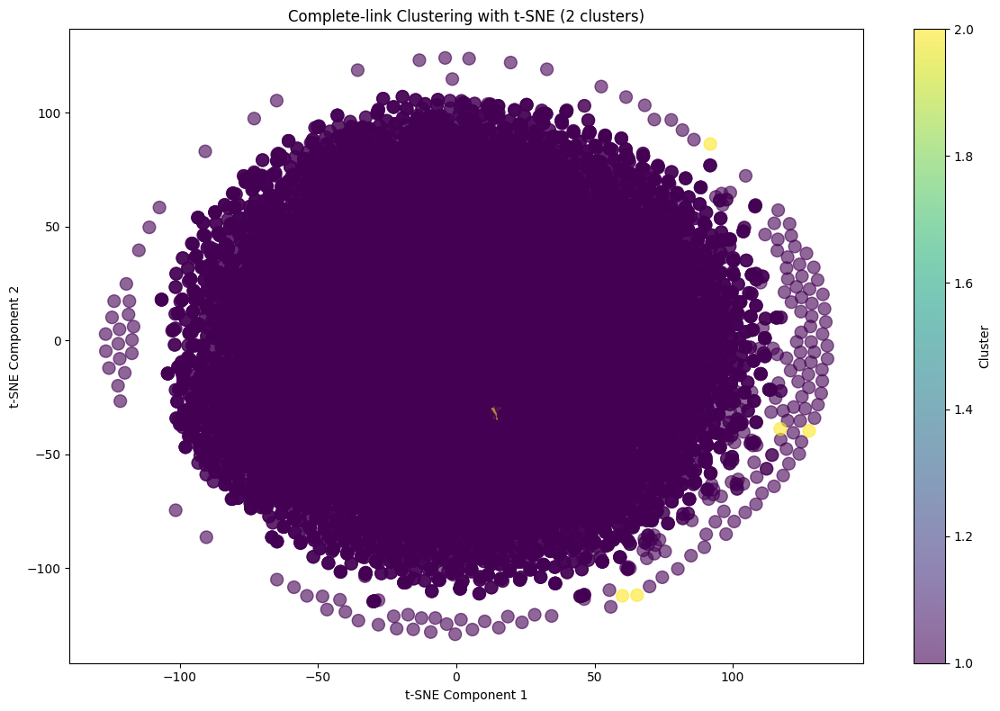

RecursionError: maximum recursion depth exceeded

<Figure size 1200x600 with 0 Axes>

In [25]:

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt

def plot_hierarchical_clustering(X, df, method='complete', text_column='Base Sentence'):
    # Perform hierarchical clustering
    linkage_matrix = linkage(X, method=method)
    
    # Create dendrogram
    plt.figure(figsize=(12, 6))
    dendrogram(linkage_matrix, labels=df[text_column].str[:20].tolist(), leaf_rotation=90)
    plt.title(f'{method.capitalize()}-link Hierarchical Clustering Dendrogram')
    plt.xlabel('Sentences')
    plt.ylabel('Distance')
    plt.tight_layout()
    plt.show()
    
    # Cut tree to get 2 clusters (to compare with k-means)
    clusters = fcluster(linkage_matrix, 2, criterion='maxclust')
    
    # Visualize with t-SNE
    tsne = TSNE(n_components=2, learning_rate='auto', init='random', perplexity=2, random_state=0).fit_transform(X)
    
    plt.figure(figsize=(12, 8))
    scatter = plt.scatter(tsne[:, 0], tsne[:, 1], c=clusters, cmap='viridis', s=100, alpha=0.6)
    
    # for i, (x, y) in enumerate(tsne):
    #     sentence = df.iloc[i][text_column]
    #     shortened = sentence[:30] + "..." if len(sentence) > 30 else sentence
    #     plt.annotate(shortened, (x, y), fontsize=8, alpha=0.7, rotation=45)
    
    plt.title(f'{method.capitalize()}-link Clustering with t-SNE (2 clusters)')
    plt.xlabel('t-SNE Component 1')
    plt.ylabel('t-SNE Component 2')
    plt.colorbar(scatter, label='Cluster')
    plt.tight_layout()
    plt.show()
    
    return clusters

# Usage
clusters_complete = plot_hierarchical_clustering(embeddings, embeddings_df, method='complete')
clusters_single = plot_hierarchical_clustering(embeddings, embeddings_df, method='single')